<a href="https://colab.research.google.com/github/Archanapy76/Simple-RNN-Model-for-Weather-Temprature-Prediction/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dropout, Dense
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
df = pd.read_csv('/content/drive/MyDrive/weatherHistory.csv')

df.head(10)

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
5,2006-04-01 05:00:00.000 +0200,Partly Cloudy,rain,9.222222,7.111111,0.85,13.9587,258.0,14.9569,0.0,1016.66,Partly cloudy throughout the day.
6,2006-04-01 06:00:00.000 +0200,Partly Cloudy,rain,7.733333,5.522222,0.95,12.3648,259.0,9.9820,0.0,1016.72,Partly cloudy throughout the day.
7,2006-04-01 07:00:00.000 +0200,Partly Cloudy,rain,8.772222,6.527778,0.89,14.1519,260.0,9.9820,0.0,1016.84,Partly cloudy throughout the day.
8,2006-04-01 08:00:00.000 +0200,Partly Cloudy,rain,10.822222,10.822222,0.82,11.3183,259.0,9.9820,0.0,1017.37,Partly cloudy throughout the day.
9,2006-04-01 09:00:00.000 +0200,Partly Cloudy,rain,13.772222,13.772222,0.72,12.5258,279.0,9.9820,0.0,1017.22,Partly cloudy throughout the day.


In [6]:
print(df.shape)
print(df.columns)
print(df.isnull().sum())

(96453, 12)
Index(['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)',
       'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
       'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover',
       'Pressure (millibars)', 'Daily Summary'],
      dtype='object')
Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64


/tmp/ipykernel_966/2260917932.py:1: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df['Formatted Date'] = pd.to_datetime(df['Formatted Date'])


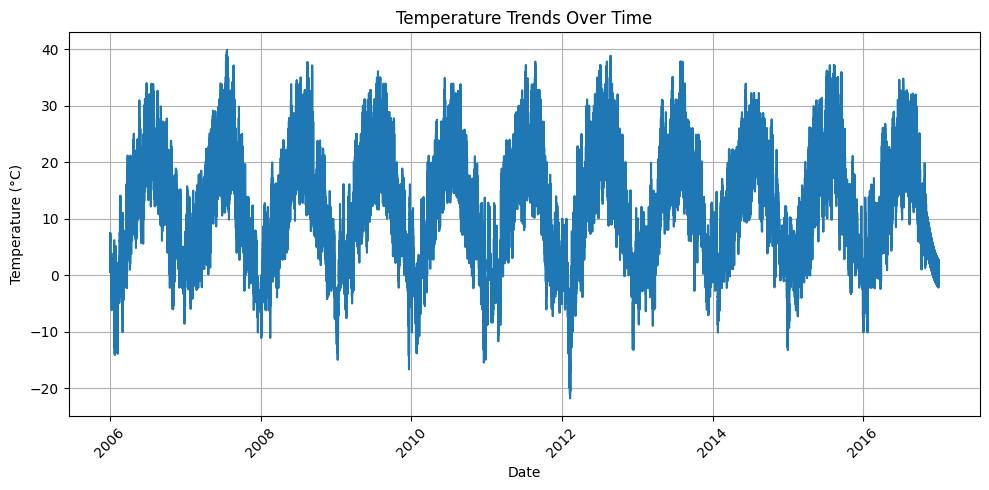

In [7]:
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'])

df = df.sort_values('Formatted Date')

plt.figure(figsize=(10, 5))
plt.plot(df['Formatted Date'], df['Temperature (C)'])

plt.title('Temperature Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
features = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Pressure (millibars)']
scaler = MinMaxScaler()

df[features] = scaler.fit_transform(df[features])
df[features].head()

,Temperature (C),Humidity,Wind Speed (km/h),Pressure (millibars)
2880,0.362884,0.89,0.268028,0.971597
2881,0.372334,0.85,0.260212,0.971110
2882,0.380524,0.82,0.317196,0.970842
2883,0.381244,0.82,0.226929,0.970546
2884,0.372694,0.86,0.218356,0.969992


In [9]:
features = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)']
weather_data = df[features].values
sequence_length = 7

X = []
y = []
for i in range(len(weather_data) - sequence_length):


    X.append(weather_data[i:i + sequence_length])


    y.append(weather_data[i + sequence_length, 0])


X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96446, 7, 3)
y shape: (96446,)


In [10]:



total_samples = len(X)

train_size = int(total_samples * 0.70)
val_size = int(total_samples * 0.15)

X_train = X[:train_size]
y_train = y[:train_size]


X_val = X[train_size:train_size + val_size]
y_val = y[train_size:train_size + val_size]


X_test = X[train_size + val_size:]
y_test = y[train_size + val_size:]


print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (67512, 7, 3)
y_train shape: (67512,)
X_val shape: (14466, 7, 3)
y_val shape: (14466,)
X_test shape: (14468, 7, 3)
y_test shape: (14468,)


In [13]:
model = Sequential([
    Input(shape=(7, 3)),

    SimpleRNN(32),

    Dropout(0.2),

    Dense(1, activation='linear')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [15]:
history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=50,
    validation_data=(X_val, y_val)
)

Epoch 1/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.0096 - mae: 0.0650 - val_loss: 5.6496e-04 - val_mae: 0.0182
Epoch 2/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0018 - mae: 0.0327 - val_loss: 6.8898e-04 - val_mae: 0.0209
Epoch 3/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 0.0011 - mae: 0.0246 - val_loss: 3.3514e-04 - val_mae: 0.0139
Epoch 4/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 8.4884e-04 - mae: 0.0220 - val_loss: 3.2067e-04 - val_mae: 0.0138
Epoch 5/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 7.6886e-04 - mae: 0.0208 - val_loss: 3.6927e-04 - val_mae: 0.0154
Epoch 6/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 7.3471e-04 - mae: 0.0202 - val_loss: 2.8699e-04 - val_mae: 0.0127
Epoch 7/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 7.1255e-04 - mae: 0.0199 - val_loss: 2.7069e-04 - val_mae: 0.0121
Epoch 8/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 7.0054e-04 - mae: 0.0196 - val_loss: 3.2297e-04 - va

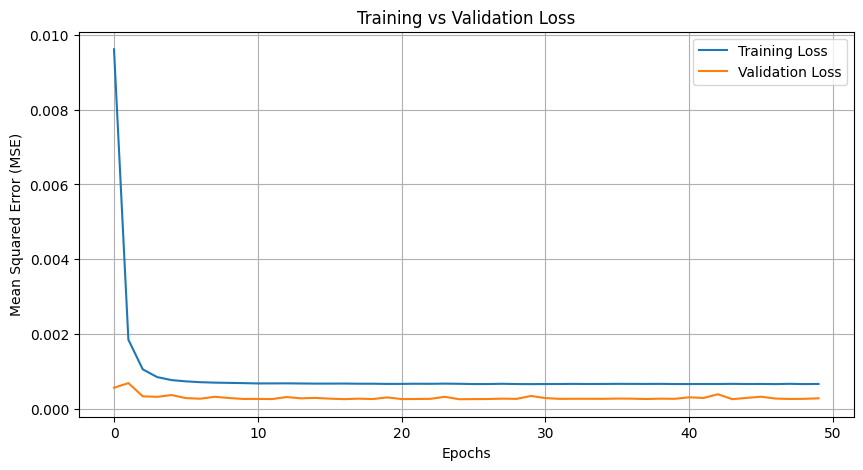

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid(True)

plt.show()

In [33]:
def inverse_temperature(values):
    values = np.asarray(values).reshape(-1)


    dummy = np.zeros((len(values), 4))


    dummy[:, 0] = values


    return scaler.inverse_transform(dummy)[:, 0]
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


y_test_actual = inverse_temperature(y_test)
y_pred_actual = inverse_temperature(y_pred_scaled)

rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
mae = mean_absolute_error(y_test_actual, y_pred_actual)
r2 = r2_score(y_test_actual, y_pred_actual)

print("RMSE:", round(rmse, 2), "°C")
print("MAE:", round(mae, 2), "°C")
print("R2 Score:", round(r2, 4))

RMSE: 1.05 °C
MAE: 0.82 °C
R2 Score: 0.987


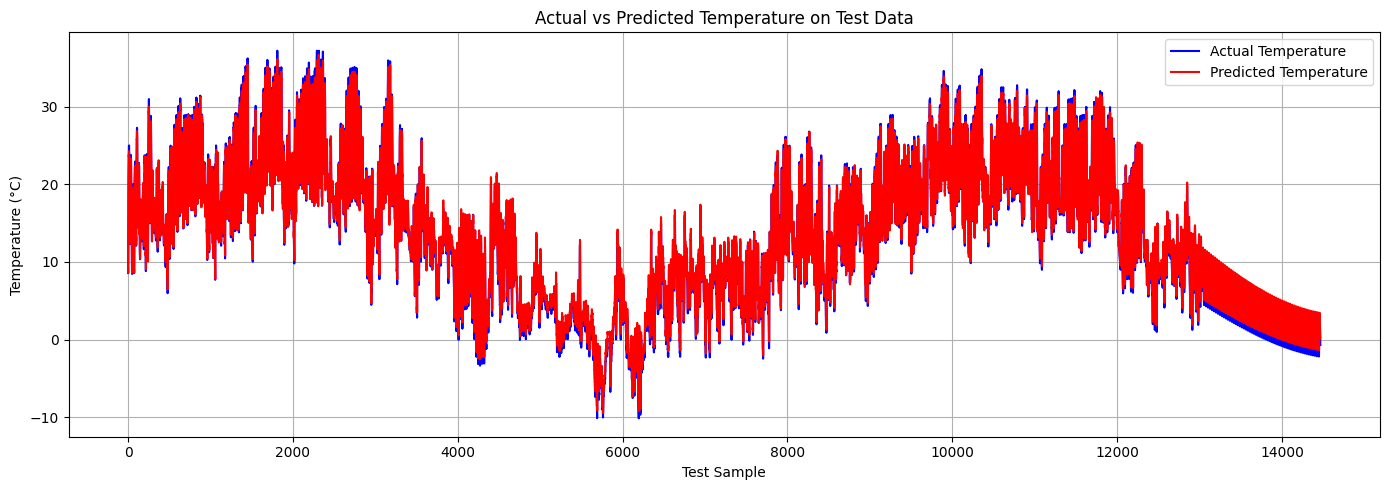

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(y_test_actual, label="Actual Temperature", color="blue")
plt.plot(y_pred_actual, label="Predicted Temperature", color="red")

plt.title("Actual vs Predicted Temperature on Test Data")
plt.xlabel("Test Sample")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [31]:
import numpy as np


last_sequence = scaled_data[-7:].copy()

future_predictions = []

for day in range(7):


    input_data = last_sequence.reshape(1, 7, 3)


    predicted_temp = model.predict(input_data, verbose=0)[0][0]


    future_predictions.append(predicted_temp)



    next_day = np.array([
        predicted_temp,
        last_sequence[-1, 1],
        last_sequence[-1, 2]
    ])


    last_sequence = np.vstack([
        last_sequence[1:],
        next_day
    ])


future_predictions = np.array(future_predictions).reshape(-1, 1)

predicted_temperatures = (
    future_predictions * scaler.data_range_[0] + scaler.data_min_[0]
)

print("Predicted temperatures for the next 7 days (°C):")
print(predicted_temperatures.flatten())

Predicted temperatures for the next 7 days (°C):
[208.05764272 152.74087643 130.25546244 114.15587906  99.49538762
  88.23943528  77.84016973]
